# 02 - Feature engineering: the customer tables

**Goal:** turn the clean transactions into two tables with **one row per customer**:
features (X) describing the customer's past, and targets (y) describing what they did next.

| Table | Features from | Targets from |
|---|---|---|
| train | everything before `config.TRAIN_CUTOFF` | the 90 days starting at `TRAIN_CUTOFF` |
| test  | everything before `config.TEST_CUTOFF`  | the 90 days starting at `TEST_CUTOFF` |

**Why this matters (leakage):** a feature may only use information that would have been available on the
cutoff date. If even one row from after the cutoff slipped into the features, the model would partly be
"reading the answer" and its test score would be too optimistic. The time filters live in
`src/features.py` (`history_before` and `label_window`), so every feature and target goes through them.

**Steps**
1. Load the clean transactions (and cancellations) from notebook 01
2. Build the train and test tables with `build_customer_table()`
3. Prove there is no leakage (three checks)
4. Compare the two tables (customers, churn rate, spend)
5. Look at who is in the population (churn rate by recency)
6. Save both tables for notebooks 03-05

In [1]:
import sys
sys.path.append("..")   # lets the notebook import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, evaluation, features

pd.set_option("display.max_columns", 50)
np.random.seed(config.RANDOM_STATE)

evaluation.set_plot_style()
CHURN = config.COLORS["churn"]   # the churn module colour (used for the churn-by-recency figure)

## 1. Load the clean data

In [2]:
tx = pd.read_parquet(config.CLEAN_FILE)              # clean purchase lines (notebook 01)
cancellations = pd.read_parquet(config.CANCEL_FILE)  # one row per cancelled invoice (notebook 01)

print(f"transactions: {len(tx):,} rows, {tx['invoice_date'].min()} to {tx['invoice_date'].max()}")
print(f"cancelled invoices: {len(cancellations):,}")

transactions: 776,577 rows, 2009-12-01 07:45:00 to 2011-12-09 12:50:00
cancelled invoices: 7,901


## 2. Build the two customer tables

The feature and target definitions (CLAUDE.md Section 8):

| Column | Meaning |
|---|---|
| `recency_days` | days from the last purchase to the cutoff |
| `frequency` | number of orders (distinct invoices) |
| `monetary` | total revenue (£) |
| `tenure_days` | days from the first purchase to the cutoff |
| `avg_order_value` | monetary / frequency |
| `n_unique_products` | number of different products bought |
| `avg_basket_size` | items (quantity) per order |
| `mean_interpurchase_days` | average days between orders = (last - first) / (frequency - 1); for one-order customers it is filled with `tenure_days` |
| `is_single_order` | 1 if the customer has only one order (flags the filled value above) |
| `revenue_last_90d`, `frequency_last_90d` | revenue and orders in the 90 days before the cutoff |
| `is_uk` | 1 if the customer's latest order was from the United Kingdom |
| `cancel_rate` | cancelled orders / (cancelled + completed orders), counting only cancellations **before** the cutoff |
| **`churned`** (target) | 1 if the customer made **no** purchase in the 90-day label window |
| **`next_period_spend`** (target) | total revenue in the 90-day label window (0 if none) |

The population of each table is every customer with at least one purchase before that cutoff.

In [3]:
train = features.build_customer_table(tx, config.TRAIN_CUTOFF, cancellations)
test = features.build_customer_table(tx, config.TEST_CUTOFF, cancellations)

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (4908, 16) | test: (5224, 16)


,customer_id,recency_days,frequency,monetary,tenure_days,avg_order_value,n_unique_products,avg_basket_size,mean_interpurchase_days,is_single_order,revenue_last_90d,frequency_last_90d,is_uk,cancel_rate,churned,next_period_spend
0,12346,133,3,77352.96,455,25784.32,25,24746.333333,160.935069,0,0.00,0,1,0.625000,1,0.00
1,12347,54,4,2434.96,212,608.74,90,406.500000,52.616435,0,636.25,1,0,0.000000,0,967.43
2,12348,56,4,1388.40,246,347.10,24,622.000000,63.275000,0,327.00,1,0,0.000000,1,0.00
3,12349,215,2,2221.14,397,1110.57,89,495.500000,181.793750,0,0.00,0,0,0.333333,1,0.00
4,12350,118,1,294.40,118,294.40,16,196.000000,118.000000,1,0.00,0,0,0.000000,1,0.00


## 3. Leakage checks

Three independent checks, each of which would fail loudly if future data leaked into the features.

**(a) The newest transaction used for features is before the cutoff.**

In [4]:
for name, cutoff in [("train", config.TRAIN_CUTOFF), ("test", config.TEST_CUTOFF)]:
    newest = features.history_before(tx, cutoff)["invoice_date"].max()
    assert newest < cutoff
    print(f"{name}: cutoff {cutoff.date()}, newest feature transaction {newest}")

train: cutoff 2011-06-01, newest feature transaction 2011-05-31 15:41:00


test: cutoff 2011-09-01, newest feature transaction 2011-08-31 17:16:00


**(b) Deleting the future changes nothing.** We rebuild the features from a copy of the data where every
transaction on or after the cutoff has been **deleted**. If the features only use the past, the result must be
identical. `assert_frame_equal` raises an error if even one value differs.

In [5]:
for name, cutoff in [("train", config.TRAIN_CUTOFF), ("test", config.TEST_CUTOFF)]:
    tx_past = tx[tx["invoice_date"] < cutoff]
    cancellations_past = cancellations[cancellations["invoice_date"] < cutoff]

    with_future = features.build_rfm(tx, cutoff).merge(
        features.build_extra_features(tx, cutoff, cancellations), on="customer_id")
    without_future = features.build_rfm(tx_past, cutoff).merge(
        features.build_extra_features(tx_past, cutoff, cancellations_past), on="customer_id")

    pd.testing.assert_frame_equal(with_future, without_future)
    print(f"{name}: features identical with and without the future rows")

train: features identical with and without the future rows


test: features identical with and without the future rows


**(c) The targets come only from the 90-day label window.**

In [6]:
for name, cutoff in [("train", config.TRAIN_CUTOFF), ("test", config.TEST_CUTOFF)]:
    window = features.label_window(tx, cutoff)
    end = cutoff + pd.Timedelta(days=config.HOLDOUT_DAYS)
    assert window["invoice_date"].min() >= cutoff and window["invoice_date"].max() < end
    print(f"{name}: labels from {window['invoice_date'].min()} to {window['invoice_date'].max()} "
          f"(window {cutoff.date()} up to, not including, {end.date()})")

train: labels from 2011-06-01 07:37:00 to 2011-08-28 16:09:00 (window 2011-06-01 up to, not including, 2011-08-30)
test: labels from 2011-09-01 08:25:00 to 2011-11-29 18:14:00 (window 2011-09-01 up to, not including, 2011-11-30)


## 4. Compare the two tables

In [7]:
def summarise(table):
    buyers = table[table["churned"] == 0]
    return pd.Series({
        "customers": len(table),
        "churn_rate": table["churned"].mean(),
        "mean_next_spend": table["next_period_spend"].mean(),
        "mean_spend_of_buyers": buyers["next_period_spend"].mean(),
        "median_spend_of_buyers": buyers["next_period_spend"].median(),
        "share_single_order": table["is_single_order"].mean(),
        "share_recency_over_365d": (table["recency_days"] > 365).mean(),
    })


summary = pd.DataFrame({"train": summarise(train), "test": summarise(test)})
evaluation.save_table(summary, "customer_tables_summary", index=True)
summary.round(3)

,train,test
customers,4908.000,5224.000
churn_rate,0.671,0.572
mean_next_spend,337.964,515.019
mean_spend_of_buyers,1025.804,1203.247
median_spend_of_buyers,427.230,522.890
share_single_order,0.315,0.303
share_recency_over_365d,0.119,0.172


**The test table looks different from the train table, as notebook 01 predicted.** The test labels fall in
September to November, the yearly peak for this giftware seller, while the train labels fall in the quiet
summer months. So in the test table **fewer customers churn** and **buyers spend more**.

What this means for the models:
- **Churn (Module 2):** ROC-AUC and PR-AUC compare the *ranking* of customers, so they are fine. But a
  probability threshold tuned on train (where churn is more common) will predict too much churn on test.
  Keep this in mind when choosing the threshold.
- **Spend (Module 3):** a model trained on summer spend will probably *under*-predict autumn spend.
- **Report:** this is a real distribution shift between the training period and the test period. It belongs in
  the Discussion / Limitations section.

## 5. Who is in the population?

Every customer who ever bought before the cutoff is included, even someone whose only order was a year and a
half earlier. How does churn depend on how long ago they last bought?

In [8]:
recency_groups = [-1, 90, 180, 365, np.inf]
group_names = ["0-90 days", "91-180", "181-365", "over 365"]


def churn_by_recency(table):
    group = pd.cut(table["recency_days"], recency_groups, labels=group_names)
    return table.groupby(group, observed=True).agg(customers=("customer_id", "size"),
                                                   churn_rate=("churned", "mean"))


by_recency = pd.concat({"train": churn_by_recency(train), "test": churn_by_recency(test)}, axis=1)
by_recency.round(3)

train                 test           
             customers churn_rate customers churn_rate
recency_days                                          
0-90 days         1976      0.437      1930      0.321
91-180             712      0.688       850      0.561
181-365           1636      0.847      1548      0.704
over 365           584      0.943       896      0.895

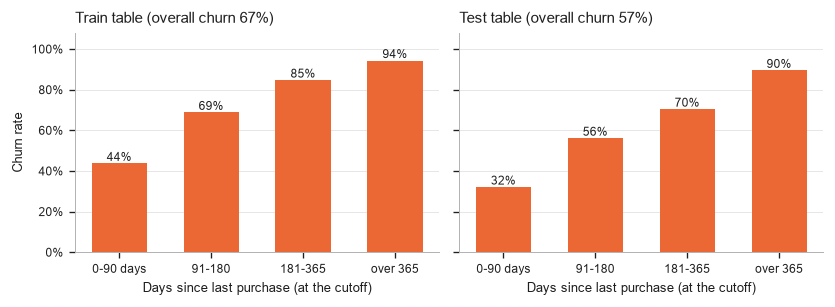

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), sharey=True)
for ax, (name, table) in zip(axes, [("Train table", train), ("Test table", test)]):
    rates = churn_by_recency(table)["churn_rate"]
    ax.bar(rates.index, rates.values, color=CHURN, width=0.6)
    for x, rate in enumerate(rates.values):
        ax.text(x, rate, f"{rate:.0%}", ha="center", va="bottom", fontsize=7)
    ax.set_title(f"{name} (overall churn {table['churned'].mean():.0%})", loc="left")
    ax.set_xlabel("Days since last purchase (at the cutoff)")
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(0, 1.08)
fig.tight_layout()
evaluation.save_fig(fig, "features_churn_by_recency")
plt.show()

**Recency alone already separates churners well**: the longer ago the last purchase, the more likely the
customer does not come back. This is why the simple rule `recency_days > 90 -> churn` is a serious baseline
in Module 2. A preview of the two baselines every model must beat:

In [10]:
baselines = {}
for name, table in [("train", train), ("test", test)]:
    majority = int(table["churned"].mean() >= 0.5)                       # predict the most common class
    rule = (table["recency_days"] > config.HOLDOUT_DAYS).astype(int)     # the recency rule
    baselines[name] = {
        "majority_class_accuracy": (table["churned"] == majority).mean(),
        "recency_rule_accuracy": (table["churned"] == rule).mean(),
    }
pd.DataFrame(baselines).round(3)

,train,test
majority_class_accuracy,0.671,0.572
recency_rule_accuracy,0.721,0.704


Customers who last bought **more than a year ago** are 12-17% of each table, and roughly 9 out of 10 of them
churn. They are easy to predict, so they push the churn scores up a little. They are kept, as agreed
(population = everyone who bought before the cutoff), because about 1 in 10 of them **does** come back. The report
should mention that the scores include these easy cases.

## 6. Feature overview (train table)

In [11]:
train.drop(columns="customer_id").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency_days,4908.0,167.82,141.37,0.00,43.00,153.00,242.00,546.00
frequency,4908.0,5.21,9.89,1.00,1.00,3.00,6.00,234.00
monetary,4908.0,2363.15,10458.52,1.55,311.38,738.31,1924.69,385971.85
tenure_days,4908.0,356.63,154.66,0.00,231.00,391.00,491.00,546.00
avg_order_value,4908.0,372.65,629.97,1.55,174.99,279.60,414.44,25784.32
n_unique_products,4908.0,70.35,97.34,1.00,17.00,40.00,87.00,1974.00
avg_basket_size,4908.0,253.12,1500.14,1.00,88.50,148.52,252.00,87167.00
mean_interpurchase_days,4908.0,138.58,132.53,0.00,43.44,85.42,198.00,546.00
is_single_order,4908.0,0.31,0.46,0.00,0.00,0.00,1.00,1.00
revenue_last_90d,4908.0,337.44,1470.32,0.00,0.00,0.00,307.38,52454.10


Things to remember for the modelling notebooks:
- `monetary`, `avg_order_value`, `avg_basket_size`, `revenue_last_90d` and `next_period_spend` are extremely
  right-skewed (the mean is far above the median; maxima are wholesalers). Use `log1p` for segmentation and for
  linear models.
- `revenue_last_90d` and `frequency_last_90d` are 0 for most customers (the median is 0).
- `is_uk` is about 92% ones: it can only help a little.

## 7. Save

Both tables are saved as parquet. Notebook 03 adds a `segment` column to both.

In [12]:
train.to_parquet(config.TRAIN_TABLE, index=False)
test.to_parquet(config.TEST_TABLE, index=False)
print(f"saved {len(train):,} customers -> {config.TRAIN_TABLE.name}")
print(f"saved {len(test):,} customers -> {config.TEST_TABLE.name}")

saved 4,908 customers -> customer_table_train.parquet
saved 5,224 customers -> customer_table_test.parquet


## 8. What we learned

- **Train table:** 4,908 customers, churn rate 67.1%. **Test table:** 5,224 customers, churn rate 57.2%.
  No missing values in either.
- **No leakage:** the newest feature transaction is before each cutoff, the features are identical when all
  future rows are deleted, and the targets come only from each 90-day window.
- **Seasonal shift:** test buyers spend more and fewer customers churn (autumn peak vs summer). Important for
  threshold choice (Module 2) and spend calibration (Module 3).
- **Strong baseline:** recency alone is very predictive (`recency_days > 90` rule accuracy about 0.70-0.72,
  vs 0.57-0.67 for always predicting "churn"). ML models must beat it on ROC-AUC/PR-AUC, not just accuracy.